Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc, and save it to folder with name $date/

In [1]:
from utils.calibration import CalibrationSignal
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
iq0_path ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:58:08_freq_11_325G_bw_2.0M_ts_1707177488.0938272_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
date = iq0_path.split('_')[-10]+'_'+iq0_path.split('_')[-9].replace(":","-")
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6
# cal0 = CalibrationSignal(iq0_path, fc, tx_freq, sample_rate) # creates an instance of CalibrationSignal. More details in utils/calibration.py 
# cal1 = CalibrationSignal(iq1_path, fc, tx_freq, sample_rate)
# cal2 = CalibrationSignal(iq2_path, fc, tx_freq, sample_rate)
# ref_sig_idx = cal0.get_all_refsigidx() # use the get_all_refsigidx() method to get the start and stop index of the reference signal
# phase_0 = cal0.get_refsig_phase(ref_sig_idx)
# phase_1 = cal1.get_refsig_phase(ref_sig_idx)
# phase_2 = cal2.get_refsig_phase(ref_sig_idx)

# t_end = ref_sig_idx[-1][1]/sample_rate  # use the stop time of the last ref sig as the duration of the file
# phase_offset_01 = np.unwrap(phase_0-phase_1)
# phase_offset_21 = np.unwrap(phase_2-phase_1)

# if not os.path.exists(date):
#     os.makedirs(date)
# # save sample_rate, date, start_time, loc_sig_idx to .mat file
# sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'ref_sig_idx': ref_sig_idx, 't_end': t_end, 'phase_offset_01': phase_offset_01, 'phase_offset_21': phase_offset_21})
# plt.plot(phase_offset_01, label='rx0    -    rx1')
# plt.plot(phase_offset_21, label='rx2    -    rx1')
# plt.xlabel('ref sig #')
# plt.legend(loc='upper right')
# plt.show()


Step 2: do the central tone tracking using matlab

In [ ]:
# need to change date first in matlab file
# matlab
# cd Starloc/
# phase_from_bin_track
# results saved to $date/res.mat

Step 3: have a look at the results

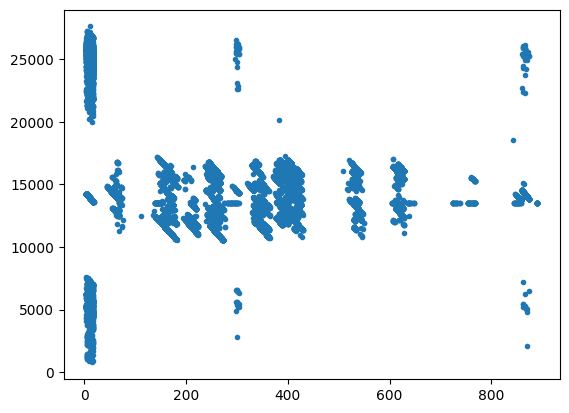

In [3]:
from matplotlib import pyplot as plt
from scipy import io as sio
res = sio.loadmat(date + '/res.mat')['res']
plt.close('all')
# %matplotlib widget
plt.plot(res[:, 0], res[:, 1], '.')
plt.show()

Step 4: simulate doppler, first need to move the tle file to the date folder with name `Starlink.tle`

In [ ]:
from sat_id import connect_doppler, doppler_sim
sim_start_time = start_time
sim_end_time = sim_start_time+t_end
sat_dopp_dict, t_list = doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

Step 5: Run `phase_from_bin.m` to get phase difference.

Step 6: Do localization based on phase diff

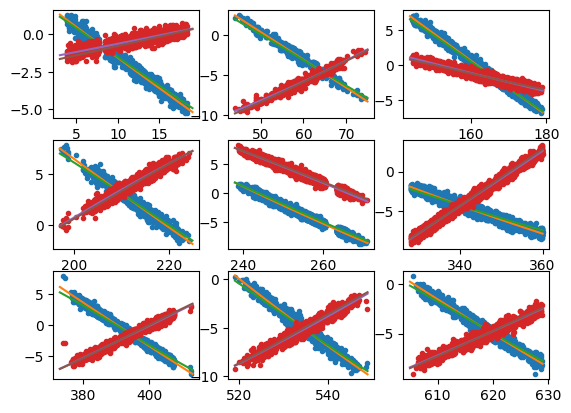

In [10]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
sat_num = len(dopp_track_dict[0, :])

# tracked tones' phase diff
del_phi_repeat_01_list, del_phi_repeat_12_list, coeff_01_list, coeff_12_list, del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list = [], [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 3e8/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real
    # time for simulated doppler
    t_sim = t_sim_list[(t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1)]
    az_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][1,:]
    el_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][2,:]
    el_gt = np.radians(el_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])
    az_gt = np.radians(az_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])

    # t_sim, az_gt, el_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, 1)
    # t_sim += t_sat_start
    # az_gt = np.radians(az_gt)
    # el_gt = np.radians(el_gt)
    loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin


    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3]))
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4]))

    range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
    range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
    range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2)
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2)
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real
    if gap_12 > 3*np.pi:
        del_phi_repeat_12 += 4*np.pi
        gap_12 -= 4*np.pi
    elif gap_12 > np.pi:
        del_phi_repeat_12 += 2*np.pi
        gap_12 -= 2*np.pi
    
    if gap_01 > 3*np.pi:
        del_phi_repeat_01 += 4*np.pi
        gap_01 -= 4*np.pi
    elif gap_01 > np.pi:
        del_phi_repeat_01 += 2*np.pi
        gap_01 -= 2*np.pi

    if gap_01 < -3*np.pi:
        del_phi_repeat_01 -= 4*np.pi
        gap_01 += 4*np.pi
    elif gap_01 < -np.pi:
        del_phi_repeat_01 -= 2*np.pi
        gap_01 += 2*np.pi


    # fit the discrete data points with polynomial (second order)
    coeff_01_list.append(np.polyfit(t_repeat, del_phi_repeat_01, 2))
    coeff_12_list.append(np.polyfit(t_repeat, del_phi_repeat_12, 2))
    del_phi_repeat_01_list.append(del_phi_repeat_01)
    del_phi_repeat_12_list.append(del_phi_repeat_12)
    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    t_sim_arr.append(t_sim)

for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(dopp_track[:, 0], del_phi_repeat_12_list[sat_idx]+np.mean(gap_12_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr), label='fit')
    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    # plt.title(str(round(gap_12,3)))
    plt.plot(dopp_track[:, 0], del_phi_repeat_01_list[sat_idx]+np.mean(gap_01_arr), '.')
    plt.plot(t_sim, np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr), label='fit')
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    # plt.title(str(round(gap_01,3)))
plt.show()

In [12]:
# do grid search
from tqdm import tqdm
x_grid, y_grid = np.linspace(-60e3, 60e3, 200), np.linspace(-60e3, 60e3, 200)
err_min = np.inf
for x in tqdm(x_grid):
    for y in y_grid:
        err = 0
        loc_1, loc_0, loc_2 = np.array([x,y,0]), np.array([x,y-d,0]), np.array([x+d,y,0])
        for sat_idx in range(sat_num):
            t_sim = t_sim_arr[sat_idx]
            mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr)
            mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr)
            mes_12_diff = np.diff(mes_12)
            mes_01_diff = np.diff(mes_01)
            
            az_gt, el_gt = az_gt_list[sat_idx], el_gt_list[sat_idx]
            loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
            range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
            range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
            del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
            del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

            err += np.sum(np.abs(mes_12-del_phi_12_gt)) + np.sum(np.abs(mes_01-del_phi_01_gt))
            # err += np.sum(np.abs(mes_12_diff-np.diff(del_phi_12_gt)))+np.sum(np.abs(mes_01_diff-np.diff(del_phi_01_gt)))
        # print(err)
        if err < err_min:
            err_min = err
            loc_min = np.array([x,y,0])


100%|██████████| 200/200 [00:13<00:00, 14.44it/s]


In [13]:
# print location (in meters)
loc_min

array([-3919.59798995, -5728.64321608,     0.        ])

In [14]:
err_min

9.208370056871171

In [15]:
err = 0
loc_1, loc_0, loc_2 = np.array([0e3,0,0]), np.array([0e3,0-d,0]), np.array([0e3+d,0,0])
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]

    t_repeat = dopp_track[:, 0]
    t_start, t_end = t_repeat[0], t_repeat[-1]
    # time for simulated doppler
    t_sim = t_sim_list[(t_sim_list > t_start-1) & (t_sim_list < t_end+1)]
    az_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][1,:]
    el_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][2,:]
    el_gt = np.radians(el_gt[((t_sim_list > t_start-1) & (t_sim_list < t_end+1))[0]])
    az_gt = np.radians(az_gt[((t_sim_list > t_start-1) & (t_sim_list < t_end+1))[0]])
    loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                        np.cos(el_gt) * np.cos(az_gt),
                        np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3]))
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4]))

    range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
    range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
    range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    mes_12 = np.polyval(coeff_12_list[sat_idx], t_sim)+np.mean(gap_12_arr)
    mes_01 = np.polyval(coeff_01_list[sat_idx], t_sim)+np.mean(gap_01_arr)
    err+= np.sum(np.abs(mes_12-del_phi_12_gt))+np.sum(np.abs(mes_01-del_phi_01_gt))
err

88.4046704837998

/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


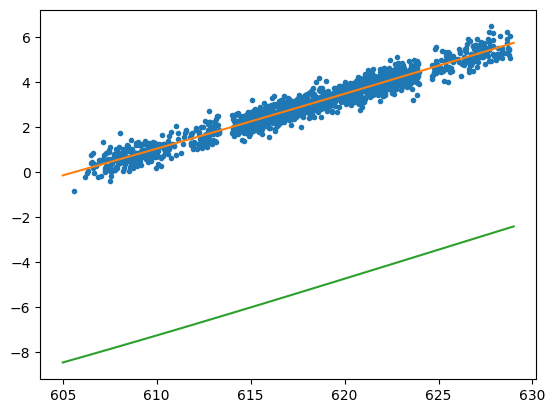

In [17]:
del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3]))
